# Expected touchdowns from the yardline (xTD model)

A deliberately simple model for the app's "TDs over expected" detector (SPEC section 7, *Sell high*): the chance that a
**pass target** or a **rush** ends in a touchdown, given only the play type and the yardline. A player's expected TDs are the sum of
those chances over his targets and carries; TDs over expected is actual minus expected.

Plan: download the 2025 play-by-play, define the plays, fit P(TD) by play type × yardline bucket with a monotone smoother,
check calibration and an out-of-sample split (fit on weeks 1-12, test on weeks 13-18), sanity-check the per-player result, and export
`data/xtd_model.json`, which the nflverse pipeline reads.

In [1]:
import json, urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression

pd.set_option('display.width', 150); pd.set_option('display.max_columns', 30)
SEASON = 2025
URL = f'https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_{SEASON}.csv.gz'
CACHE = Path('..') / '.cache' / 'nflverse'          # gitignored
OUT = Path('..') / 'data' / 'xtd_model.json'
CACHE.mkdir(parents=True, exist_ok=True)
PBP = CACHE / f'play_by_play_{SEASON}.csv.gz'
if PBP.exists() and PBP.stat().st_size > 1_000_000:
    print('using cached', PBP, f'({PBP.stat().st_size / 1e6:.1f} MB)')
else:
    print('downloading', URL)
    urllib.request.urlretrieve(URL, PBP)
    print('saved', PBP, f'({PBP.stat().st_size / 1e6:.1f} MB)')

using cached ../.cache/nflverse/play_by_play_2025.csv.gz (19.1 MB)


## Which plays count

nflverse labels plays `pass` and `run`. A **pass target** is a `pass` play with an intended receiver (`receiver_player_id` present), which includes
incompletions but excludes sacks and throwaways. A **rush** is a `run` play with a rusher, which includes QB scrambles and designed QB runs. Both are
regular-season only (`season_type == 'REG'`). Two-point tries are dropped (they are not scrimmage touchdowns). The outcome is the *offense's*
touchdown on the play (`pass_touchdown` or `rush_touchdown`); defensive and return touchdowns are not the receiver's or rusher's.

In [2]:
cols = ['season', 'season_type', 'week', 'play_type', 'yardline_100', 'pass_touchdown', 'rush_touchdown', 'two_point_attempt',
        'receiver_player_id', 'receiver_player_name', 'rusher_player_id', 'rusher_player_name', 'posteam']
raw = pd.read_csv(PBP, usecols=cols, low_memory=False)
reg = raw[(raw.season_type == 'REG') & (raw.two_point_attempt.fillna(0) == 0) & raw.yardline_100.between(1, 99)].copy()
reg['yl'] = reg.yardline_100.astype(int)
passes = reg[(reg.play_type == 'pass') & reg.receiver_player_id.notna()].assign(kind='pass', td=lambda d: d.pass_touchdown.fillna(0).astype(int),
            pid=lambda d: d.receiver_player_id, name=lambda d: d.receiver_player_name)
rushes = reg[(reg.play_type == 'run') & reg.rusher_player_id.notna()].assign(kind='rush', td=lambda d: d.rush_touchdown.fillna(0).astype(int),
            pid=lambda d: d.rusher_player_id, name=lambda d: d.rusher_player_name)
plays = pd.concat([passes, rushes], ignore_index=True)[['week', 'kind', 'yl', 'td', 'pid', 'name', 'posteam']]
print(plays.groupby('kind').agg(plays=('td', 'size'), tds=('td', 'sum'), td_rate=('td', 'mean')).round(4))
print('weeks', plays.week.min(), '-', plays.week.max(), '| yardline range', plays.yl.min(), '-', plays.yl.max())

      plays  tds  td_rate
kind                     
pass  16609  811   0.0488
rush  14168  510   0.0360
weeks 1 - 18 | yardline range 1 - 99


## Buckets

Finer near the goal line, where the touchdown chance changes fast: 1, 2, 3, 4-5, 6-10, 11-15, 16-20, 21-30, 31-50, 51-99
(`yardline_100` runs 1-99 on scrimmage plays; the request's "51-100" bucket is 51-99 in practice). The same bucket edges are used for passes and rushes.

In [3]:
EDGES = [(1, 1), (2, 2), (3, 3), (4, 5), (6, 10), (11, 15), (16, 20), (21, 30), (31, 50), (51, 99)]
def bucket_of(yl):
    for i, (a, b) in enumerate(EDGES):
        if a <= yl <= b: return i
plays['b'] = plays.yl.map(bucket_of)
label = lambda i: f'{EDGES[i][0]}' if EDGES[i][0] == EDGES[i][1] else f'{EDGES[i][0]}-{EDGES[i][1]}'
raw_tab = plays.groupby(['kind', 'b']).agg(n=('td', 'size'), tds=('td', 'sum'), rate=('td', 'mean')).reset_index()
raw_tab['bucket'] = raw_tab.b.map(label)
raw_tab.pivot(index='b', columns='kind', values=['n', 'tds', 'rate']).round(4).set_axis([label(i) for i in range(len(EDGES))])

n            tds           rate        
kind     pass    rush   pass   rush    pass    rush
1        79.0   263.0   46.0  146.0  0.5823  0.5551
2        98.0   133.0   53.0   59.0  0.5408  0.4436
3        79.0   125.0   36.0   35.0  0.4557  0.2800
4-5     219.0   244.0  104.0   61.0  0.4749  0.2500
6-10    519.0   543.0  148.0   74.0  0.2852  0.1363
11-15   641.0   619.0  115.0   33.0  0.1794  0.0533
16-20   655.0   612.0   75.0   22.0  0.1145  0.0359
21-30  1448.0  1339.0  109.0   23.0  0.0753  0.0172
31-50  3893.0  3289.0   90.0   32.0  0.0231  0.0097
51-99  8978.0  7001.0   35.0   25.0  0.0039  0.0036

## Smoothing: a monotone fit

Raw bucket rates are noisy where there is little data (the 1-yard bucket for passes has only a few hundred plays; deep buckets have
very few touchdowns), and raw rates can even run the wrong way between neighbouring buckets. Football gives us one safe constraint: **the
touchdown chance cannot increase as the ball moves farther from the goal line.** So the fit is **isotonic regression** (pool adjacent
violators) on the per-yardline rates, decreasing in yardline and weighted by the number of plays at each yard, separately for passes and rushes.
Each bucket's probability is the play-weighted average of that smooth curve over the yards in the bucket, so the bucket values are monotone too.

It needs no functional form and keeps the heavily sampled shape exactly. As a check it is compared out of sample (below) with the raw bucket
rates and with a logistic regression on `log(yardline)`.

In [4]:
YARDS = np.arange(1, 100)
def per_yard(df):
    g = df.groupby('yl').td.agg(['size', 'sum']).reindex(YARDS, fill_value=0)
    return g['size'].values, g['sum'].values

def fit_curve(df, method='isotonic'):
    """Returns p(yardline) for yards 1..99 for one play type."""
    n, t = per_yard(df)
    if method == 'raw':        # bucket rates, no smoothing
        out = np.zeros(len(YARDS))
        for a, b in EDGES:
            m = (YARDS >= a) & (YARDS <= b); out[m] = t[m].sum() / max(n[m].sum(), 1)
        return out
    if method == 'logistic':   # logit p = a + b * log(yardline)
        X = np.log(df.yl.values).reshape(-1, 1)
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(X, df.td.values)
        return lr.predict_proba(np.log(YARDS).reshape(-1, 1))[:, 1]
    ok = n > 0
    iso = IsotonicRegression(increasing=False, y_min=0, y_max=1, out_of_bounds='clip')
    iso.fit(YARDS[ok], t[ok] / n[ok], sample_weight=n[ok])
    return iso.predict(YARDS)

def to_buckets(curve, df):
    """Play-weighted bucket averages of a per-yard curve, plus the sample size n per bucket."""
    n, _ = per_yard(df); rows = []
    for a, b in EDGES:
        m = (YARDS >= a) & (YARDS <= b); w = n[m]
        rows.append(dict(yardline_from=a, yardline_to=b, p_td=float(np.average(curve[m], weights=w)) if w.sum() else float(curve[m].mean()), n=int(w.sum())))
    return rows

def fit_all(df, method='isotonic'):
    return {k: to_buckets(fit_curve(df[df.kind == k], method), df[df.kind == k]) for k in ('pass', 'rush')}

def predict(model, df):
    """Per-play P(TD) from a bucket model."""
    out = np.zeros(len(df))
    for k in ('pass', 'rush'):
        lut = np.zeros(100)
        for b in model[k]: lut[b['yardline_from']:b['yardline_to'] + 1] = b['p_td']
        m = (df.kind == k).values; out[m] = lut[df.yl.values[m]]
    return out

## Out-of-sample check: fit on weeks 1-12, test on weeks 13-18

Same fit on the early weeks only, scored on the late weeks it never saw. Log loss and Brier score (lower is better) against three alternatives:
a single rate per play type (no yardline at all), the raw bucket rates and the logistic fit on `log(yardline)`.

In [5]:
train, test = plays[plays.week <= 12], plays[plays.week >= 13]
print(f'train {len(train):,} plays ({train.td.sum()} TDs)   test {len(test):,} plays ({test.td.sum()} TDs)')
eps = 1e-6
def scores(p, y):
    p = np.clip(p, eps, 1 - eps)
    return dict(log_loss=float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))), brier=float(np.mean((p - y) ** 2)), predicted_tds=float(p.sum()), actual_tds=int(y.sum()))
res = {}
flat = {k: float(train[train.kind == k].td.mean()) for k in ('pass', 'rush')}
res['flat rate per play type'] = scores(test.kind.map(flat).values, test.td.values)
for name, method in [('raw buckets', 'raw'), ('logistic on log(yardline)', 'logistic'), ('isotonic buckets (chosen)', 'isotonic')]:
    res[name] = scores(predict(fit_all(train, method), test), test.td.values)
oos = pd.DataFrame(res).T
oos

train 20,217 plays (871 TDs)   test 10,560 plays (450 TDs)


,log_loss,brier,predicted_tds,actual_tds
flat rate per play type,0.175685,0.040759,451.369505,450.0
raw buckets,0.122532,0.032730,455.033216,450.0
logistic on log(yardline),0.123508,0.032618,441.909921,450.0
isotonic buckets (chosen),0.122315,0.032655,455.032564,450.0


In [6]:
m_train = fit_all(train)
tt = test.assign(p=predict(m_train, test))
cal = tt.groupby(['kind', 'b']).agg(n=('td', 'size'), predicted=('p', 'mean'), actual=('td', 'mean'), tds=('td', 'sum'), expected=('p', 'sum')).reset_index()
cal['bucket'] = cal.b.map(label); cal['diff'] = cal.actual - cal.predicted
# a rough 95% band for the actual rate in each bucket (binomial)
cal['se'] = np.sqrt(cal.predicted * (1 - cal.predicted) / cal.n); cal['within_2se'] = (cal['diff'].abs() <= 2 * cal.se) | (cal.n < 30)
print('Out-of-sample calibration, weeks 13-18, model fit on weeks 1-12')
cal[['kind', 'bucket', 'n', 'predicted', 'actual', 'expected', 'tds', 'within_2se']].round(4)

Out-of-sample calibration, weeks 13-18, model fit on weeks 1-12


,kind,bucket,n,predicted,actual,expected,tds,within_2se
0,pass,1,24,0.5440,0.7500,13.0560,18,True
1,pass,2,28,0.5440,0.4643,15.2320,13,True
2,pass,3,28,0.5042,0.4643,14.1176,13,True
3,pass,4-5,79,0.4806,0.4304,37.9684,34,True
4,pass,6-10,197,0.3261,0.2183,64.2391,43,False
5,pass,11-15,225,0.1827,0.1778,41.1105,40,True
6,pass,16-20,212,0.1093,0.1226,23.1771,26,True
7,pass,21-30,482,0.0741,0.0768,35.7059,37,True
8,pass,31-50,1323,0.0222,0.0249,29.3428,33,True
9,pass,51-99,2920,0.0040,0.0038,11.5682,11,True


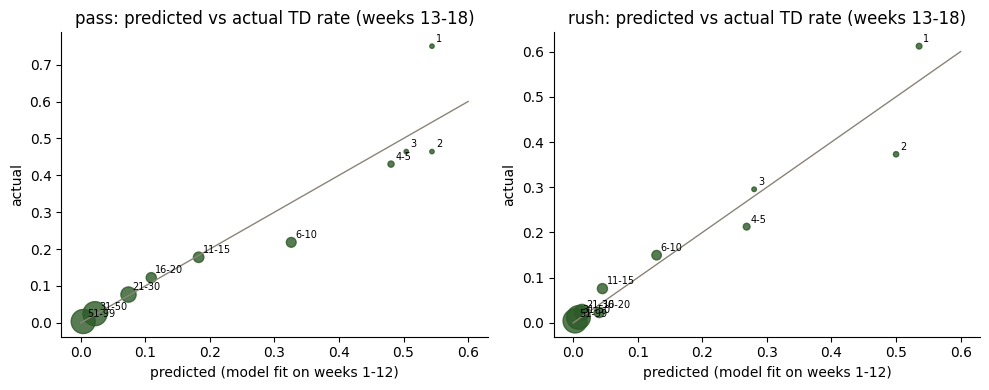

totals on the test weeks: predicted 455.0 actual 450


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, k in zip(axes, ('pass', 'rush')):
    c = cal[cal.kind == k]
    ax.plot([0, 0.6], [0, 0.6], color='#8a8478', lw=1)
    ax.scatter(c.predicted, c.actual, s=np.clip(c.n / 4, 10, 300), color='#2d5a27', alpha=0.8)
    for _, r in c.iterrows(): ax.annotate(r.bucket, (r.predicted, r.actual), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.set_title(f'{k}: predicted vs actual TD rate (weeks 13-18)'); ax.set_xlabel('predicted (model fit on weeks 1-12)'); ax.set_ylabel('actual')
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()
print('totals on the test weeks: predicted', round(float(tt.p.sum()), 1), 'actual', int(tt.td.sum()))

## Final fit and in-sample calibration

The exported model is fit on **all** 2025 regular-season plays (weeks 1-18). The table is the bucket probability, the raw bucket rate it
was smoothed from, and the sample size.

In [8]:
final = fit_all(plays)
rawm = fit_all(plays, 'raw')
tab = []
for k in ('pass', 'rush'):
    for f, r in zip(final[k], rawm[k]):
        tab.append(dict(play_type=k, yardline=f"{f['yardline_from']}" if f['yardline_from'] == f['yardline_to'] else f"{f['yardline_from']}-{f['yardline_to']}", n=f['n'], raw_rate=r['p_td'], p_td=f['p_td']))
bucket_table = pd.DataFrame(tab)
display(bucket_table.pivot(index='yardline', columns='play_type', values=['n', 'raw_rate', 'p_td']).reindex([label(i) for i in range(len(EDGES))]).round(4))
for k in ('pass', 'rush'):
    p = [b['p_td'] for b in final[k]]
    assert all(x >= y - 1e-12 for x, y in zip(p, p[1:])), f'{k} buckets must not increase with distance'
ins = plays.assign(p=predict(final, plays))
print('in-sample: predicted', round(float(ins.p.sum()), 1), 'actual', int(ins.td.sum()), '| by play type:', ins.groupby('kind').agg(p=('p', 'sum'), a=('td', 'sum')).round(1).to_dict('index'))

n         raw_rate            p_td        
play_type    pass    rush     pass    rush    pass    rush
yardline                                                  
1            79.0   263.0   0.5823  0.5551  0.5823  0.5551
2            98.0   133.0   0.5408  0.4436  0.5408  0.4436
3            79.0   125.0   0.4557  0.2800  0.4772  0.2800
4-5         219.0   244.0   0.4749  0.2500  0.4671  0.2500
6-10        519.0   543.0   0.2852  0.1363  0.2852  0.1363
11-15       641.0   619.0   0.1794  0.0533  0.1794  0.0546
16-20       655.0   612.0   0.1145  0.0359  0.1151  0.0386
21-30      1448.0  1339.0   0.0753  0.0172  0.0750  0.0163
31-50      3893.0  3289.0   0.0231  0.0097  0.0234  0.0097
51-99      8978.0  7001.0   0.0039  0.0036  0.0038  0.0034

in-sample: predicted 1321.0 actual 1321 | by play type: {'pass': {'p': 811.0, 'a': 811}, 'rush': {'p': 510.0, 'a': 510}}


## Per-player sanity check: 2025 TDs over expected

Expected TDs = the sum of the model's P(TD) over a player's targets and carries (a player's receiving and rushing opportunities
together); TDs over expected = actual minus expected. Players need at least 40 opportunities. Large positive values should be red-zone and goal-line finishers
(or lucky), large negative values should be players who get the looks but not the scores.

In [9]:
by = ins.groupby('pid').agg(name=('name', 'last'), team=('posteam', 'last'), opps=('td', 'size'), tds=('td', 'sum'), xtd=('p', 'sum'))
by['over'] = by.tds - by.xtd
elig = by[by.opps >= 40].sort_values('over', ascending=False)
print('Top 10 TDs over expected, 2025 regular season')
display(elig.head(10).round(2))
print('Bottom 5')
display(elig.tail(5).round(2))
print(f'{len(elig)} players with 40+ opportunities; league-wide TDs {int(by.tds.sum())} vs expected {by.xtd.sum():.1f}; SD of TDs over expected {elig.over.std():.2f}')

Top 10 TDs over expected, 2025 regular season


,name,team,opps,tds,xtd,over
pid,,,,,,
00-0039139,J.Gibbs,DET,337,18,11.92,6.08
00-0034857,J.Allen,BUF,94,14,8.43,5.57
00-0036410,T.Higgins,CIN,98,11,6.03,4.97
00-0034351,D.Goedert,PHI,82,11,6.28,4.72
00-0036223,J.Taylor,IND,378,20,15.60,4.40
00-0040691,J.Dart,NYG,79,9,4.74,4.26
00-0038608,K.Boutte,NE,46,6,1.90,4.10
00-0038543,J.Smith-Njigba,SEA,170,10,6.17,3.83
00-0039040,D.Achane,MIA,323,12,8.33,3.67


Bottom 5


,name,team,opps,tds,xtd,over
pid,,,,,,
00-0037256,R.White,TB,177,4,7.41,-3.41
00-0040583,W.Marks,HOU,232,5,8.57,-3.57
00-0040128,T.Warren,IND,118,5,8.66,-3.66
00-0033280,C.McCaffrey,SF,440,17,21.45,-4.45
00-0036322,J.Jefferson,MIN,143,2,7.05,-5.05


228 players with 40+ opportunities; league-wide TDs 1321 vs expected 1321.0; SD of TDs over expected 1.83


## Export

`data/xtd_model.json` in the format the nflverse pipeline reads: `version`, `fit_season`, and `buckets` with `play_type`, inclusive
`yardline_from` / `yardline_to` (of `yardline_100`), `p_td` and `n`. The cell re-reads the file and checks that each play type's buckets
cover 1-99 exactly once.

In [10]:
OUT.parent.mkdir(parents=True, exist_ok=True)
model = dict(version=1, fit_season=SEASON, buckets=[
    dict(play_type=k, yardline_from=b['yardline_from'], yardline_to=b['yardline_to'], p_td=round(b['p_td'], 5), n=b['n'])
    for k in ('pass', 'rush') for b in final[k]])
OUT.write_text(json.dumps(model, indent=2) + '\n')
back = json.loads(OUT.read_text())
assert set(back) == {'version', 'fit_season', 'buckets'} and back['version'] == 1 and back['fit_season'] == SEASON
for k in ('pass', 'rush'):
    cover = sorted(y for b in back['buckets'] if b['play_type'] == k for y in range(b['yardline_from'], b['yardline_to'] + 1))
    assert cover == list(range(1, 100)), k
    assert all(set(b) == {'play_type', 'yardline_from', 'yardline_to', 'p_td', 'n'} for b in back['buckets'] if b['play_type'] == k)
print('wrote', OUT.resolve(), '|', len(back['buckets']), 'buckets covering yardlines 1-99 for pass and rush')

wrote /Users/krish/Projects/personal/fantasy app/data/xtd_model.json | 20 buckets covering yardlines 1-99 for pass and rush


## Conclusion

**The model is good enough for its job** (a "TDs over expected" flag), and it is simple enough to explain: the chance a target or carry becomes a
touchdown depends on the play type and how far from the goal line it starts. A goal-line carry (yard 1) scores about 56% of the time and a
target there about 58%; from the 6-10 yard bucket it is 29% for a pass and 14% for a rush; beyond the 50 it is under 0.5% for both.

* **Out of sample (fit on weeks 1-12, scored on 13-18):** log loss 0.1223 against 0.1757 for a single rate per play type, so the yardline carries nearly all
  the signal. The smoothed buckets edge the raw bucket rates (0.1225) and the logistic on log(yardline) (0.1235), but only marginally: with 20,000+ plays the raw
  rates are already stable. The monotone fit earns its place by guaranteeing no bucket scores higher than a nearer one, not by a big accuracy gain.
  Predicted 455 TDs on the test weeks against 450 actual.
* **Calibration:** 18 of the 20 play-type × bucket cells land within two standard errors of the actual rate; the two that do not (passes from 6-10 yards, 0.33
  predicted vs 0.22; rushes from 11-15, 0.045 vs 0.076) are about what chance gives across 20 cells. In-sample, predicted and actual TDs match exactly by construction.
* **Players:** the top "TDs over expected" names are goal-line backs, a rushing QB and red-zone targets (Gibbs, Josh Allen, Higgins, Goedert, Taylor), and the negative end is led by
  high-volume players who did not score. The SD of TDs over expected is about 1.8, so the app should treat a gap of roughly +/-3 TDs or more as a real flag, not 1 or 2.

**Limits.** The model ignores down, distance, team, game script and who is playing, so it will over-credit a short-yardage specialist's usage and under-credit
a goal-line back on a bad offense. Pass probabilities attach to the *target*, so a receiver is credited the same chance whether or not the throw is catchable. One season of data.
Bucket values and sample sizes are in `data/xtd_model.json`; re-run this notebook with a later season and bump `fit_season` when that becomes worthwhile.